# Stroke classification with a multi-input GRU

```
acc  x ─┐
acc  y ─┤
acc  z ─┤   v_t = [ax ay az gx gy gz]      ┌─────┐
gyro x ─┼──> (one 6-vector per 10 ms) ───> │ GRU │ ──> FC ──> softmax ──> [p_serve, p_forehand, p_backhand, p_volley]
gyro y ─┤                                  └─────┘
gyro z ─┘
```

Model and training code live in `ml/stroke_gru.py`. The GRU reads the 100-sample (1 s) TennisEye window one 6-channel
vector at a time. Its last hidden state goes through a small fully connected head to 4 class **logits**, and softmax turns
those into class probabilities.

- **Classes:** serve, forehand, backhand, volley (forehand and backhand volleys merged: only 33 shots).
- **Input scaling:** by sensor full scale (acc / 16 g, gyro / 2000 °/s). These are the same ranges as our ICM-20948 firmware,
  so the trained model can run on our own sensor stream.
- **Augmentation:** random sensor-frame rotation up to 15° (the same rotation applied to acc and gyro, standing in for
  different sensor mounting), ±80 ms time shift, ±10% amplitude scaling, and noise.
- **Evaluation:**
  - **leave-one-subject-out (LOSO):** the model is trained on 6 players and tested on the 7th, i.e. how it does for a new user;
  - **mixed-player 5-fold:** every player appears in training, i.e. how it does once a user's own swings are in the training set.

The previous notebook (`analysis.ipynb`) is the baseline: a random forest on hand-crafted features scored 55% LOSO accuracy
(macro-F1 0.43).

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

sys.path.insert(0, "../ml")
import stroke_gru as sg

sns.set_theme(style="whitegrid", context="notebook")
device = "cuda" if torch.cuda.is_available() else "cpu"
X, y, groups, shots = sg.load_tenniseye()
CLASSES = np.array(sg.CLASSES)
print(f"X {X.shape}, device {device}")
display(pd.crosstab(shots.player_id, CLASSES[y], margins=True))

m = sg.StrokeGRU()
print(m)
print(f"{sum(p.numel() for p in m.parameters()):,} parameters")

X (2013, 100, 6), device cuda


col_0,backhand,forehand,serve,volley,All
player_id,,,,,
1,4,9,36,0,49
2,69,145,75,13,302
3,66,70,50,0,186
4,62,240,0,4,306
5,158,470,0,16,644
6,35,83,263,0,381
7,0,0,145,0,145
All,394,1017,569,33,2013


StrokeGRU(
  (gru): GRU(6, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=4, bias=True)
  )
)
43,204 parameters


## 1. Leave-one-subject-out: does it generalise to a new player?

In [2]:
def loso(cfg: sg.TrainConfig):
    proba = np.zeros((len(y), len(CLASSES)), dtype=np.float32)
    for p in np.unique(groups):
        tr, te = groups != p, groups == p
        model = sg.train_model(X[tr], y[tr], cfg, device=device)
        proba[te] = sg.predict(model, X[te])
    return proba

def scores(proba, mask=slice(None)):
    pred = proba.argmax(1)
    return dict(accuracy=(pred[mask] == y[mask]).mean(), macro_f1=f1_score(y[mask], pred[mask], average="macro"))

results, probas = {}, {}
for name, cfg in [("GRU, no augmentation", sg.TrainConfig(augment=False)),
                  ("GRU + augmentation", sg.TrainConfig(augment=True))]:
    t0 = time.time()
    probas[name] = loso(cfg)
    results[name] = scores(probas[name])
    print(f"{name}: {time.time() - t0:.0f} s")
results["Random forest (analysis.ipynb)"] = dict(accuracy=0.55, macro_f1=0.43)
pd.DataFrame(results).T.style.format("{:.2f}")

GRU, no augmentation: 28 s


GRU + augmentation: 39 s


,accuracy,macro_f1
"GRU, no augmentation",0.47,0.41
GRU + augmentation,0.53,0.44
Random forest (analysis.ipynb),0.55,0.43


pred                backhand  forehand  serve  volley
player_id true                                       
1         backhand         4         0      0       0
          forehand         0         5      4       0
          serve            0         1     35       0
2         backhand        45         7      7      10
          forehand        13       121      6       5
          serve            5        59      3       8
          volley           3         7      1       2
3         backhand        55         9      0       2
          forehand         5        47      0      18
          serve            1         0     49       0
4         backhand        48         0     14       0
          forehand        13         1    226       0
          volley           1         0      3       0
5         backhand        88        26     21      23
          forehand         8       353     99      10
          volley           4         5      1       6
6         backhand        34         0      0       1
          forehand         6        76      0       1
          serve            0       259      4       0
7         serve           12        48     84       1

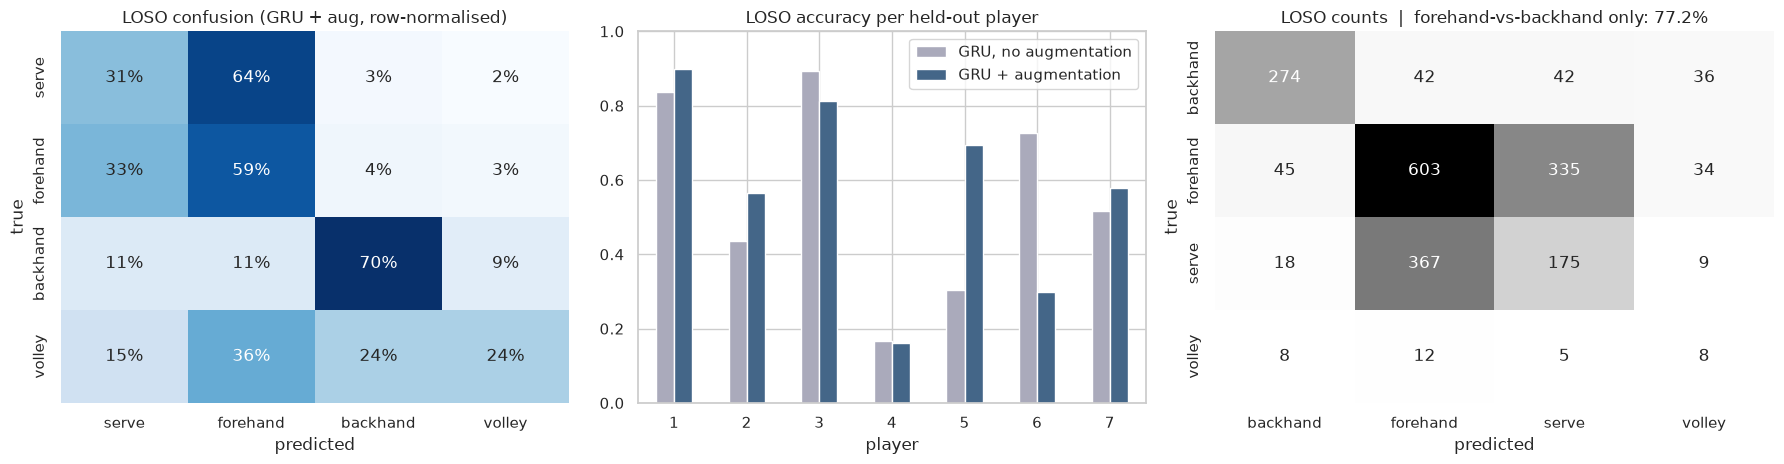

In [3]:
proba = probas["GRU + augmentation"]
pred = proba.argmax(1)

fig, axs = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
cm = confusion_matrix(y, pred, normalize="true")
sns.heatmap(cm, annot=True, fmt=".0%", xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues", cbar=False, ax=axs[0])
axs[0].set(title="LOSO confusion (GRU + aug, row-normalised)", xlabel="predicted", ylabel="true")

per_player = pd.DataFrame({name: [(p.argmax(1)[groups == g] == y[groups == g]).mean() for g in np.unique(groups)]
                           for name, p in probas.items()}, index=np.unique(groups))
per_player.plot.bar(ax=axs[1], rot=0, color=["#aab", "#468"])
axs[1].set(title="LOSO accuracy per held-out player", xlabel="player", ylim=(0, 1))

# Forehand vs. backhand only (the groundstroke side of the problem)
gs = np.isin(y, [1, 2])
fb_pred = np.where(proba[gs][:, 1] >= proba[gs][:, 2], 1, 2)
fb_acc = (fb_pred == y[gs]).mean()
cm_sf = pd.crosstab(pd.Series(CLASSES[y], name="true"), pd.Series(CLASSES[pred], name="predicted"))
sns.heatmap(cm_sf, annot=True, fmt="d", cmap="Greys", cbar=False, ax=axs[2])
axs[2].set(title=f"LOSO counts  |  forehand-vs-backhand only: {fb_acc:.1%}")
plt.tight_layout()

pd.crosstab([shots.player_id, pd.Series(CLASSES[y], name="true")], pd.Series(CLASSES[pred], name="pred"))

## 2. Mixed-player 5-fold: performance once the player's swings are in training

27 s
Mixed-player 5-fold: accuracy 90.5%, macro-F1 0.75


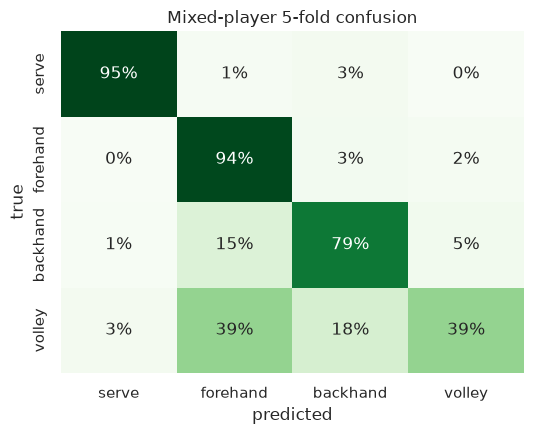

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
proba_mix = np.zeros_like(proba)
t0 = time.time()
for tr, te in skf.split(X, y):
    model = sg.train_model(X[tr], y[tr], sg.TrainConfig(augment=True), device=device)
    proba_mix[te] = sg.predict(model, X[te])
print(f"{time.time() - t0:.0f} s")
mix = scores(proba_mix)
print(f"Mixed-player 5-fold: accuracy {mix['accuracy']:.1%}, macro-F1 {mix['macro_f1']:.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y, proba_mix.argmax(1), normalize="true"), annot=True, fmt=".0%",
            xticklabels=CLASSES, yticklabels=CLASSES, cmap="Greens", cbar=False, ax=ax)
ax.set(title="Mixed-player 5-fold confusion", xlabel="predicted", ylabel="true")
plt.tight_layout()

## 3. Final model and inference

The final model is trained on all 2013 shots and saved to `ml/checkpoints/stroke_gru.pt`.
That folder is gitignored because the weights are derived from the license-restricted dataset.
Below is an example of inference on single shots: the logits and the softmax output.

In [5]:
cfg = sg.TrainConfig(augment=True)
final = sg.train_model(X, y, cfg, device=device)
ckpt = sg.CKPT_DIR / "stroke_gru.pt"
sg.save(final, cfg, ckpt)
print(f"saved {ckpt}")

model = sg.load(ckpt, device=device)
rows = []
for c in range(len(CLASSES)):
    i = int(np.flatnonzero(y == c)[0])
    xb = torch.tensor(X[i:i + 1], device=device)
    with torch.no_grad():
        logits = model(xb)[0]
    p = torch.softmax(logits, -1).cpu().numpy()
    rows.append({"shot": i, "true": CLASSES[c], "logits": np.round(logits.cpu().numpy(), 2),
                 **{f"p_{k}": v for k, v in zip(CLASSES, p)}, "predicted": CLASSES[p.argmax()]})
pd.DataFrame(rows).style.format({f"p_{k}": "{:.2f}" for k in CLASSES})

saved /home/neckles/projects/qtennis/ml/checkpoints/stroke_gru.pt


,shot,true,logits,p_serve,p_forehand,p_backhand,p_volley,predicted
0,1,serve,[ 6.76 -2.82 -2.69 -4.69],1.00,0.00,0.00,0.00,serve
1,0,forehand,[-3.62 3.79 0.45 -1.44],0.00,0.96,0.03,0.01,forehand
2,10,backhand,[-1.52 -0.04 3.18 -2.71],0.01,0.04,0.95,0.00,backhand
3,68,volley,[-2.87 1.62 0.02 0.95],0.01,0.58,0.12,0.30,forehand



## 4. Findings

| setting | accuracy | macro-F1 |
|---|---|---|
| LOSO, random forest on hand-crafted features (baseline) | 55% | 0.43 |
| LOSO, GRU, no augmentation | 47% | 0.41 |
| LOSO, GRU + augmentation | 53% | 0.44 |
| **Mixed-player 5-fold, GRU + augmentation** | **90.5%** | **0.75** |

- **With the player's own swings in training, the GRU works well:** 95% of serves, 94% of forehands and 79% of backhands are correct.
  Volleys stay poor (39%) because there are only 33 of them.
- **On an unseen player it does no better than the hand-crafted baseline.** Almost all the error is serve vs. forehand: 64% of serves
  are called forehands, and 33% of forehands are called serves. Forehand vs. backhand alone is 77%.
  The failures are one-sided per player: player 4's forehands become serves (226 of 240), and player 6's serves become forehands (259 of 263).
  To a handle-mounted IMU in a 1 s window around impact, a serve and a forehand are similar wrist motions, and with only five
  players who serve, individual style decides which way the model leans.
- **Augmentation helps on average** (+6 points LOSO), mostly for player 5. It doesn't help players 4 and 6.
  Per-player LOSO numbers also move a lot between configurations (player 6: 73% → 30%), so with 7 subjects they are noisy.
  Treat differences of a few points as noise.

**What this means for qtennis**
1. **Plan for per-user calibration.** The 47–53% → 90% gap says recording a few labelled swings of each stroke from each user
   (then fine-tuning the head, or the whole GRU) matters more than any change to the model.
2. **A longer window would likely fix serve vs. forehand.** The serve toss, the racket drop behind the head, and the overhead contact
   happen with the racket in a very different orientation relative to gravity. That shows up in the slow, low-acceleration
   part of the motion, more than 0.5 s before impact, which TennisEye's 1 s window mostly cuts off. Our own firmware streams
   continuously, so we can capture 2–3 s windows.
3. **The model is device-compatible.** Inputs are scaled by full scale (16 g, 2000 °/s), the same ranges as our ICM-20948 firmware.
   Use `scale_imu(x, acc_unit="g")` on the firmware's `D,...` stream, resampled to 100 Hz with a 100-sample window centred on the
   impact (the jerk peak). Check the axis orientation against TennisEye's handle mounting before relying on it.
